# 05 — Cost simulation: does predictive maintenance save money?

**Stand-in data.** NASA turbofan simulation data stands in for rotating equipment. Not real field data.
**All costs are ASSUMPTIONS** (`configs/costs.yaml`), not real company or industry figures.

**Phase 5 "done" line:** cost-per-engine table for all three strategies, chosen threshold, sensitivity chart,
key numbers in `reports/results.json` (written by `python -m src.train`; this notebook checks it matches).

**Setup.** The 100 train engines run to failure, so we know each one's life L. RUL predictions are the Phase 3
cross-validated ones (`data/processed/rul_oof.csv`): each engine predicted by models that never saw it.

| Strategy | Rule | Cost per engine |
|---|---|---|
| Run to failure | never replace early | failure (+ unplanned downtime) |
| Fixed schedule | replace at cycle N | planned (+ downtime) + wasted life × (L − N); failure if L ≤ N |
| Predictive (lower bound) | when the range's lower bound ≤ T, replace after the lead time | as above; failure if the engine dies first |
| Predictive (point estimate) | same, using the single prediction | as above |

N and T for each engine are chosen on the **other** engines (5 engine-grouped folds), then scored on it.
*Caveat:* the other engines' predictions came from models that saw this engine; that touches only the choice of one number.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
print("interpreter:", sys.executable)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import cost_sim as cs
from src.data import load_config

cfg, costs = load_config(), cs.load_costs()
SC, LEAD = cfg["cost_sim"], costs["maintenance_lead_cycles"]
FIG_DIR = ROOT / cfg["paths"]["figures"]
results = json.loads((ROOT / "reports" / "results.json").read_text())
oof = pd.read_csv(ROOT / cfg["paths"]["processed"] / "rul_oof.csv")
lives, tables = cs.schedules(oof, cfg["data"]["rul_cap"])
rows = cs.evaluate(lives, tables, costs, LEAD, SC["n_folds"])
FAIL, PLANNED = cs.event_costs(costs)

BLUE, ORANGE, AQUA, GRAY, INK, INK2 = "#2a78d6", "#eb6834", "#1baf7a", "#b5b4ae", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRAY,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "font.size": 9,
})
print("ASSUMED costs:", {k: v for k, v in costs.items() if k not in ("currency", "assumption")})
print(f"one failure = ${FAIL:,.0f}; one planned replacement = ${PLANNED:,.0f} (downtime included)")

interpreter: C:\Users\A\Documents\NASA-project\.venv\Scripts\python.exe


ASSUMED costs: {'unplanned_failure_cost': 100000, 'planned_replacement_cost': 20000, 'downtime_cost_per_cycle': 5000, 'unplanned_downtime_cycles': 10, 'planned_downtime_cycles': 2, 'wasted_life_cost_per_cycle': 100, 'maintenance_lead_cycles': 5}
one failure = $150,000; one planned replacement = $30,000 (downtime included)


## 1. Cost per engine, held-out engines

In [2]:
table = cs.summarize(rows, costs)
sav = cs.savings(rows, costs, SC["bootstrap"], cfg["seed"])
sav_point = cs.savings(rows, costs, SC["bootstrap"], cfg["seed"], "predictive_point")
chosen = cs.best_settings(lives, tables, costs, LEAD)
lo95, hi95 = sav["savings_vs_best_alternative_95range"]

assert np.isclose(sav["savings_vs_best_alternative"], results["cost"]["savings_lower_bound_policy"]["savings_vs_best_alternative"]), \
    "notebook and results.json disagree: re-run python -m src.train"
print(f"Predictive (lower bound) vs {cs.LABELS[sav['best_alternative']]}: {sav['savings_vs_best_alternative']:.1%} cheaper per engine "
      f"(95% range {lo95:.1%} to {hi95:.1%}); vs run to failure: {sav['savings_vs_run_to_failure']:.1%}")
print(f"cross-check, cost per operating cycle: {sav['savings_per_operating_cycle_vs_best_alternative']:.1%} cheaper than the fixed schedule")
print(f"Predictive (point estimate) vs fixed: {sav_point['savings_vs_best_alternative']:.1%}")
print(f"chosen settings on all 100 engines: fixed N = {chosen['fixed']} cycles; "
      f"threshold T = {chosen['predictive_lo']} cycles on the lower bound (+ {LEAD}-cycle lead time); "
      f"T = {chosen['predictive_point']} on the point estimate")
table.round(1)

Predictive (lower bound) vs Fixed schedule: 18.1% cheaper per engine (95% range 8.6% to 24.9%); vs run to failure: 78.7%
cross-check, cost per operating cycle: 35.4% cheaper than the fixed schedule
Predictive (point estimate) vs fixed: 17.6%
chosen settings on all 100 engines: fixed N = 127 cycles; threshold T = 5 cycles on the lower bound (+ 5-cycle lead time); T = 15 on the point estimate


,mean_cost_per_engine,cost_per_operating_cycle,failures,planned_replacements,mean_wasted_cycles_when_planned,setting_range_across_folds
Run to failure,150000.0,727.061219,100,0,0.0,0-0
Fixed schedule,38997.0,243.104254,1,99,78.757576,127-134
Predictive (lower bound),31953.0,156.95744,1,99,7.606061,4-5
Predictive (point estimate),32143.0,158.472166,1,99,9.525253,11-15


In [3]:
# which engines failed under each strategy, and why
fails = rows.loc[rows[[f"{s}_failed" for s in cs.STRATEGIES[1:]]].any(axis=1),
                 ["life", "fixed_setting", "fixed_replace_at", "predictive_lo_setting", "predictive_lo_replace_at",
                  "predictive_point_setting", "predictive_point_replace_at"]]
fails

,life,fixed_setting,fixed_replace_at,predictive_lo_setting,predictive_lo_replace_at,predictive_point_setting,predictive_point_replace_at
engine,,,,,,,
39,128,134,134.0,5,119.0,11,121.0
51,213,127,127.0,4,213.0,15,209.0
84,267,134,134.0,5,257.0,11,270.0


## 2. The money chart: where each strategy's cost goes

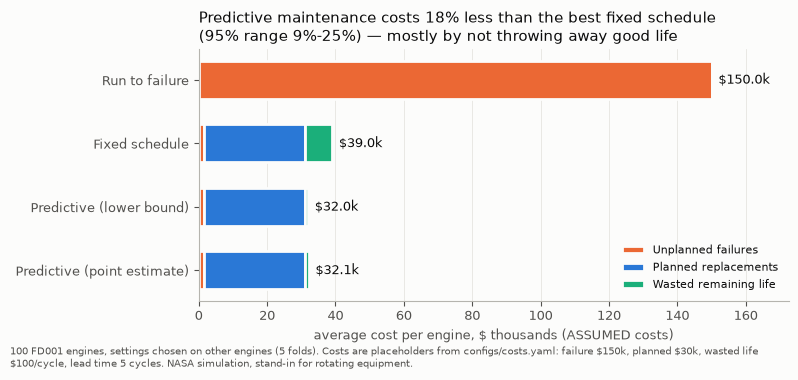

In [4]:
parts = pd.DataFrame({
    cs.LABELS[s]: {
        "Unplanned failures": rows[f"{s}_failed"].mean() * FAIL,
        "Planned replacements": (~rows[f"{s}_failed"]).mean() * PLANNED,
        "Wasted remaining life": rows[f"{s}_wasted"].mean() * costs["wasted_life_cost_per_cycle"],
    } for s in cs.STRATEGIES
}).T.iloc[::-1] / 1000

fig, ax = plt.subplots(figsize=(8, 3.6))
left = np.zeros(len(parts))
for col, color in zip(parts.columns, [ORANGE, BLUE, AQUA]):
    ax.barh(parts.index, parts[col], left=left, color=color, height=0.6, label=col, edgecolor="#fcfcfb", linewidth=2)
    left += parts[col].to_numpy()
for y, total in enumerate(left):
    ax.text(total + 2, y, f"${total:,.1f}k", va="center", color=INK, fontsize=9)
ax.set(xlabel="average cost per engine, $ thousands (ASSUMED costs)", xlim=(0, left.max() * 1.15))
ax.set_title(f"Predictive maintenance costs {sav['savings_vs_best_alternative']:.0%} less than the best fixed schedule\n"
             f"(95% range {lo95:.0%}-{hi95:.0%}) — mostly by not throwing away good life", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
ax.legend(loc="lower right", frameon=False, fontsize=8)
fig.text(0.01, -0.03, f"100 FD001 engines, settings chosen on other engines (5 folds). Costs are placeholders from configs/costs.yaml: "
         f"failure \\${FAIL/1000:.0f}k, planned \\${PLANNED/1000:.0f}k, wasted life \\${costs['wasted_life_cost_per_cycle']}/cycle, "
         f"lead time {LEAD} cycles. NASA simulation, stand-in for rotating equipment.", fontsize=7, color=INK2, wrap=True)
fig.tight_layout()
fig.savefig(FIG_DIR / "cost_strategies.png", dpi=130, bbox_inches="tight")
plt.show()

## 3. Sensitivity: when does predictive stop paying?

Each point re-chooses N and T (engine-grouped) under the changed assumption. Band = 95% bootstrap range over engines.
Savings are vs the cheapest non-predictive strategy (fixed schedule at every point here).

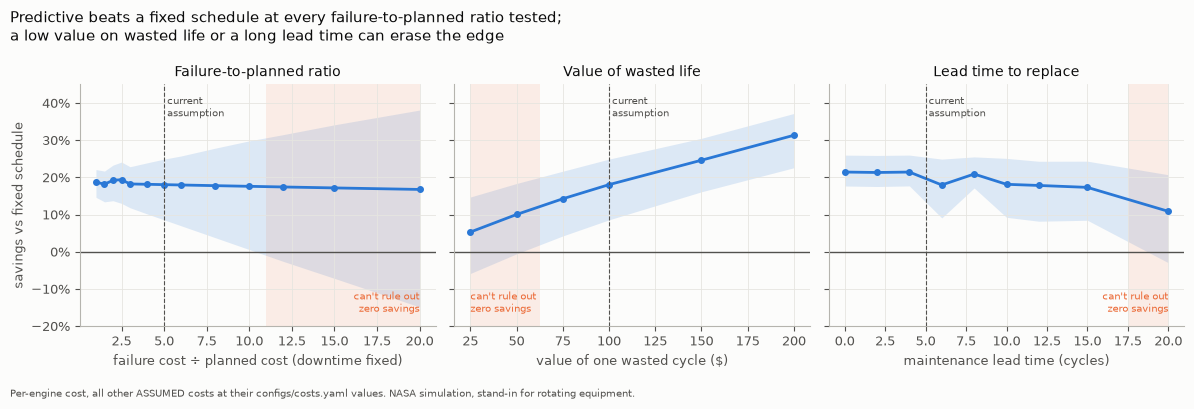

--- Failure-to-planned ratio


,best_alternative,savings_vs_best_alternative,low95,high95,savings_per_operating_cycle,predictive_failures
ratio,,,,,,
1.0,fixed,0.187,0.147,0.221,0.328,1
1.5,fixed,0.182,0.134,0.217,0.335,1
2.0,fixed,0.192,0.137,0.233,0.358,1
2.5,fixed,0.194,0.130,0.241,0.360,1
3.0,fixed,0.183,0.118,0.229,0.354,1
4.0,fixed,0.182,0.102,0.239,0.354,1
5.0,fixed,0.181,0.086,0.249,0.354,1
6.0,fixed,0.180,0.070,0.258,0.354,1
8.0,fixed,0.178,0.038,0.279,0.354,1


--- Value of wasted life


,best_alternative,savings_vs_best_alternative,low95,high95,savings_per_operating_cycle,predictive_failures
waste,,,,,,
25,fixed,0.053,-0.058,0.147,0.354,1
50,fixed,0.100,-0.005,0.184,0.354,1
75,fixed,0.143,0.043,0.217,0.354,1
100,fixed,0.181,0.086,0.249,0.354,1
150,fixed,0.246,0.161,0.305,0.354,1
200,fixed,0.313,0.226,0.372,0.370,1


--- Lead time to replace


,best_alternative,savings_vs_best_alternative,low95,high95,savings_per_operating_cycle,predictive_failures
lead,,,,,,
0,fixed,0.215,0.177,0.260,0.383,0
2,fixed,0.213,0.176,0.259,0.382,0
4,fixed,0.214,0.177,0.260,0.383,0
6,fixed,0.180,0.091,0.249,0.353,1
8,fixed,0.209,0.172,0.255,0.376,0
10,fixed,0.182,0.093,0.251,0.355,1
12,fixed,0.178,0.082,0.243,0.352,1
15,fixed,0.173,0.085,0.244,0.345,1
20,fixed,0.109,-0.029,0.207,0.290,3


In [5]:
sens = {p: cs.sensitivity(lives, tables, costs, cfg, p) for p in ["ratio", "waste", "lead"]}
current = {"ratio": costs["unplanned_failure_cost"] / costs["planned_replacement_cost"],
           "waste": costs["wasted_life_cost_per_cycle"], "lead": LEAD}
xlabel = {"ratio": "failure cost ÷ planned cost (downtime fixed)",
          "waste": "value of one wasted cycle ($)", "lead": "maintenance lead time (cycles)"}
title = {"ratio": "Failure-to-planned ratio", "waste": "Value of wasted life", "lead": "Lead time to replace"}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, p in zip(axes, sens):
    d = sens[p]
    ax.fill_between(d.index, d.low95, d.high95, color=BLUE, alpha=0.15, linewidth=0)
    ax.plot(d.index, d.savings_vs_best_alternative, color=BLUE, linewidth=2, marker="o", markersize=4)
    ax.axhline(0, color=INK2, linewidth=1)
    ax.axvline(current[p], color=INK2, linewidth=0.8, linestyle="--")
    ax.text(current[p], 0.42, " current\n assumption", color=INK2, fontsize=7, va="top")
    x = d.index.to_numpy(dtype=float)
    edges = np.concatenate([[x[0]], (x[1:] + x[:-1]) / 2, [x[-1]]])  # shade halfway to each neighbour
    unsure = np.where(d.low95 <= 0)[0]
    for i in unsure:
        ax.axvspan(edges[i], edges[i + 1], color=ORANGE, alpha=0.10, linewidth=0)
    if len(unsure):
        at_end = unsure[-1] == len(x) - 1
        ax.text(edges[unsure[-1] + 1] if at_end else edges[unsure[0]], -0.17, "can't rule out\nzero savings",
                color=ORANGE, fontsize=7, va="bottom", ha="right" if at_end else "left")
    ax.set(title=title[p], xlabel=xlabel[p], ylim=(-0.2, 0.45))
    ax.title.set_fontsize(10)
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
axes[0].set_ylabel("savings vs fixed schedule")
fig.suptitle("Predictive beats a fixed schedule at every failure-to-planned ratio tested;\n"
             "a low value on wasted life or a long lead time can erase the edge", x=0.01, ha="left", fontsize=11)
fig.text(0.01, -0.04, "Per-engine cost, all other ASSUMED costs at their configs/costs.yaml values. "
         "NASA simulation, stand-in for rotating equipment.", fontsize=7, color=INK2)
fig.tight_layout()
fig.savefig(FIG_DIR / "cost_sensitivity.png", dpi=130, bbox_inches="tight")
plt.show()
for p, d in sens.items():
    print(f"--- {title[p]}"); display(d.round(3))

## 4. Checks

- **Leakage:** RUL predictions are out-of-fold (Phase 3); N and T are chosen on other engines (tested in `tests/test_cost_sim.py`).
- **Cost math:** failure vs replace branches, lead time turning a warning into a failure, wasted life — all tested.
- **results.json** matches this notebook (assert in section 1).
- **Cost per operating cycle** (no wasted-life price needed) points the same way, more strongly.

## 5. Conclusions (all costs are ASSUMPTIONS)

### Cost per engine, 100 held-out engines

| Strategy | Setting | Cost / engine | Failures | Wasted life when replaced |
|---|---|---|---|---|
| Run to failure | — | $150.0k | 100 | — |
| Fixed schedule | replace at cycle 127 | $39.0k | 1 | 79 cycles |
| **Predictive (lower bound)** | **replace when lower bound ≤ 5 cycles (+5-cycle lead time)** | **$32.0k** | **1** | **7.6 cycles** |
| Predictive (point estimate) | replace when prediction ≤ 15 cycles (+5) | $32.1k | 1 | 9.5 cycles |

**Headline for the deck:** under the assumed costs, predictive maintenance costs **18% less than the best fixed schedule
(95% range 9–25%)** and **79% less than run-to-failure**.

1. **Chosen threshold: lower bound ≤ 5 cycles**, then replace 5 cycles later. In words: act when the model can no longer say
   "at least 5 more cycles, 95% sure". Stable across folds (4–5).
2. **The saving comes from not throwing away good life, not from avoiding failures.** Fixed and predictive each have one failure;
   the fixed schedule discards ~79 cycles per engine, predictive ~8.
3. **The cross-check is stronger:** per operating cycle (no price on wasted life needed), predictive is **35% cheaper** — the
   fixed schedule pays for its next replacement much sooner. The 18% per-engine headline is the conservative number.
4. **Lower bound vs point estimate: a tie** (18.1% vs 17.6%). Once the threshold is chosen by cost, the point-estimate policy just
   picks a higher threshold (15 vs 5). On this data the range does not save extra money; its value is a decision rule people can read.
   The deck should not claim the range itself saves money.
5. **The failures:** predictive engine 51 had its replacement scheduled for cycle 213 — the cycle it failed (missed by 0 cycles).
   Fixed-schedule engine 39 lived 128 cycles, below the N = 134 chosen in its fold.

### When does predictive stop paying?
- **Failure-to-planned ratio:** never, between 1:1 and 20:1 — savings stay 17–19%, because the fixed schedule barely fails here.
  From 12:1 upward the 95% range includes zero: with failures that expensive, one unlucky failure decides the result.
- **Value of wasted life:** the real driver of the per-engine number. 5% at $25/cycle and 10% at $50/cycle (95% ranges touch zero)
  up to 31% at $200/cycle.
- **Lead time:** ~21% with 0–4 cycles, 17–18% with 6–15, 11% at 20 cycles (3 failures; 95% range includes zero).
- **So:** predictive stops being clearly worth it if wasted life is valued below ~$50 per cycle, or if replacing takes 20+ cycles
  after the alert.

### Limits
- **All costs are placeholders**, not real company or industry figures.
- **FD001 has no early-life failures** (shortest life 128 cycles), which makes a fixed schedule unusually safe. Equipment with
  early or random failures would likely favour predictive more — a hypothesis this data cannot test.
- **Simulated end of life is very predictable** (Phase 3: RMSE 3.7 with ≤ 25 cycles left), which is why a 5-cycle threshold works.
  Real data would need a larger safety margin.
- **100 engines:** the bootstrap range (9–25%) is the honest size of the uncertainty.
- One replacement per engine life; no spare-part logistics, crew limits or multiple failure modes.
